```
Density-based clustering of plant images (CPSC 480 Phase 3, Group 2).

Question: can DBSCAN group plant photos by species without seeing the labels, and does a
version that adapts to crowded/empty areas (Local-Scaling DBSCAN) do better?

Two datasets: Flowers-102 and PlantNet-300K (20 species x 100 images each).
Pipeline: MobileNetV2 turns each photo into 1,280 numbers -> UMAP shrinks them to 15 ->
four clustering methods (k-means, DBSCAN, Local-Scaling DBSCAN, HDBSCAN) -> scores.

```

In [1]:
import random
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")   # hides harmless UMAP / scikit-learn warnings

# settings (change these if you want)
N_CLASSES = 20        # species / classes per dataset
PER_CLASS = 100       # images per class
MIN_PTS = 30          # DBSCAN MinPts (2 x 15 dimensions)
UMAP_DIMS = 15
SEEDS = [0, 1, 2, 3, 4]
DATASETS = ["Flowers102", "PlantNet300K"]

# __file__ only exists when running a .py script; added try for use in Jupyter Notebook
try:
    base_dir = Path(__file__).resolve().parent
except NameError:
    base_dir = Path.cwd()

In [2]:
# 1. get the images and turn them into embeddings
# a pretrained CNN (MobileNetV2) describes every photo with 1,280 numbers. This is slow, so the
# result is saved in <dataset>_embeddings.npz and reused the next time.

PLANTNET_URL = "https://zenodo.org/records/5645731/files/plantnet_300K.zip?download=1"
TRAIN_PATTERN = re.compile(r"(?:^|/)(?:images_)?train/([^/]+)/([^/]+\.(?:jpe?g|png))$", re.I)


def download_plantnet_subset(folder):
    """Pull only 20 random species x 100 train images out of the 31.7 GB Zenodo zip."""
    from remotezip import RemoteZip   # reads single files from the zip over the internet

    rng = random.Random(0)
    zip_file = RemoteZip(PLANTNET_URL)
    species = {}
    for name in zip_file.namelist():
        match = TRAIN_PATTERN.search(name)
        if match:
            species.setdefault(match.group(1), []).append(name)
    eligible = sorted(s for s, files in species.items() if len(files) >= PER_CLASS)
    chosen = sorted(rng.sample(eligible, N_CLASSES))
    print("PlantNet species chosen (seed 0):", chosen)
    for s in chosen:
        (folder / s).mkdir(parents=True, exist_ok=True)
        for name in rng.sample(sorted(species[s]), PER_CLASS):
            (folder / s / Path(name).name).write_bytes(zip_file.read(name))


def embed_images(dataset):
    """Run every image through MobileNetV2 (classifier removed) -> 1,280 numbers per image."""
    import torch
    from torch.utils.data import DataLoader
    from torchvision import models

    device = "cuda" if torch.cuda.is_available() else "cpu"
    net = models.mobilenet_v2(weights="IMAGENET1K_V1").eval().to(device)
    net.classifier = torch.nn.Identity()
    features, labels = [], []
    with torch.no_grad():
        for images, y in DataLoader(dataset, batch_size=64, num_workers=0):
            features.append(net(images.to(device)).cpu().numpy())
            labels.append(np.asarray(y))
    return np.vstack(features), np.concatenate(labels)


def load_embeddings(name):
    cache = base_dir / f"{name}_embeddings.npz"
    if cache.exists():
        data = np.load(cache)
        return data["X"], data["y"]

    from torch.utils.data import ConcatDataset, Subset
    from torchvision import datasets, transforms

    tf = transforms.Compose([
        transforms.Resize((224, 224)),   # 224 x 224 RGB
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    rng = random.Random(0)
    if name == "Flowers102":
        parts = [datasets.Flowers102(base_dir / "data", split=s, download=True, transform=tf)
                 for s in ("train", "val", "test")]
        everything = ConcatDataset(parts)
        targets = sum([list(p._labels) for p in parts], [])
        counts = np.bincount(targets)
        eligible = [c for c in range(len(counts)) if counts[c] >= PER_CLASS]
        classes = sorted(rng.sample(eligible, N_CLASSES))
        picked = []
        for c in classes:
            pool = [i for i, t in enumerate(targets) if t == c]
            picked += rng.sample(pool, PER_CLASS)
        X, y_raw = embed_images(Subset(everything, picked))
        y = np.array([classes.index(int(v)) for v in y_raw])
    else:   # PlantNet300K
        folder = base_dir / "plantnet_subset"
        if not folder.exists():
            download_plantnet_subset(folder)
        X, y = embed_images(datasets.ImageFolder(folder, transform=tf))

    np.savez(cache, X=X, y=y)
    print(f"{name}: saved embeddings {X.shape}")
    return X, y

In [3]:
# 2. Helper functions: choosing epsilon, the clustering variants, held-out assignment, scores

def knee_eps(Z, k):
    """Epsilon from the k-distance 'elbow': sort every point's distance to its k-th neighbour
    and take the point farthest from the straight line joining the first and last points."""
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    kd = np.sort(d[:, -1])
    x = np.linspace(0, 1, kd.size)
    y = (kd - kd.min()) / (kd.max() - kd.min() + 1e-12)
    return float(kd[np.argmax(x - y)]), kd


def scaled_distances(Z, k):
    """Local scaling: divide each distance by sqrt(s_i * s_j), where s_i is the distance from
    point i to its k-th neighbour. In empty areas s is big (distances shrink); in crowded areas
    s is small (distances grow). Plain DBSCAN is then run on these scaled distances."""
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    s = d[:, -1]
    return euclidean_distances(Z) / np.sqrt(np.outer(s, s) + 1e-12), s


def knee_eps_scaled(Dn, k):
    kd = np.sort(np.sort(Dn, axis=1)[:, k])
    x = np.linspace(0, 1, kd.size)
    y = (kd - kd.min()) / (kd.max() - kd.min() + 1e-12)
    return float(kd[np.argmax(x - y)]), kd


def assign_to_core(Z_train, model, Z_test, eps):
    """DBSCAN cannot label new points, so each test point joins the cluster of its nearest
    core point (from the training set) if that core point is within eps; otherwise noise."""
    cores = model.core_sample_indices_
    if len(cores) == 0:
        return -np.ones(len(Z_test), dtype=int)
    d, j = NearestNeighbors(n_neighbors=1).fit(Z_train[cores]).kneighbors(Z_test)
    labels = model.labels_[cores][j[:, 0]]
    labels[d[:, 0] > eps] = -1
    return labels


def assign_to_core_scaled(Z_train, model, s_train, Z_test, eps, k):
    """Same idea for Local-Scaling DBSCAN, using scaled distances."""
    cores = model.core_sample_indices_
    if len(cores) == 0:
        return -np.ones(len(Z_test), dtype=int)
    d, _ = NearestNeighbors(n_neighbors=k).fit(Z_train).kneighbors(Z_test)
    s_test = d[:, -1]
    Dn = euclidean_distances(Z_test, Z_train[cores]) / np.sqrt(np.outer(s_test, s_train[cores]) + 1e-12)
    j = Dn.argmin(axis=1)
    labels = model.labels_[cores][j]
    labels[Dn[np.arange(len(j)), j] > eps] = -1
    return labels


def score(Z, y_true, labels):
    """ARI counts noise (-1) as its own group. Silhouette and purity use clustered points only;
    coverage = share of points that are not noise (read purity together with coverage)."""
    labels = np.asarray(labels)
    kept = labels != -1
    n_clusters = len(set(labels[kept]))
    purity = np.nan
    if kept.any():
        correct = sum(np.bincount(y_true[labels == c]).max() for c in set(labels[kept]))
        purity = correct / kept.sum()
    silhouette = np.nan
    if n_clusters > 1 and kept.sum() > n_clusters:
        silhouette = silhouette_score(Z[kept], labels[kept])
    return {"clusters": n_clusters, "noise": 1 - kept.mean(),
            "ARI": adjusted_rand_score(y_true, labels),
            "purity": purity, "coverage": kept.mean(), "silhouette": silhouette}

In [4]:
# 3. run the experiment on each dataset
# for each dataset and each seed: 80/20 split -> UMAP (fitted on the 80% only) -> epsilon from
# the elbow -> four methods -> scores on the 80% and on the held-out 20%. An epsilon sweep
# (0.5x to 1.8x the elbow value) shows how sensitive DBSCAN and Local-Scaling DBSCAN are.

all_rows, sweep_rows, per_species = [], [], []
first_run = {}   # kept from seed 0 for the figures

for name in DATASETS:
    X, y = load_embeddings(name)
    print(f"\n{name}: {X.shape[0]} images, {len(set(y))} classes")

    for seed in SEEDS:
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
        reducer = umap.UMAP(n_components=UMAP_DIMS, n_neighbors=15, min_dist=0.0,
                            random_state=seed, n_jobs=1).fit(X_tr)
        Z_tr, Z_te = reducer.embedding_, reducer.transform(X_te)

        # standard DBSCAN
        eps, kdist = knee_eps(Z_tr, MIN_PTS)
        db = DBSCAN(eps=eps, min_samples=MIN_PTS).fit(Z_tr)
        # Local-Scaling DBSCAN
        Dn, s_tr = scaled_distances(Z_tr, MIN_PTS)
        eps_s, kdist_s = knee_eps_scaled(Dn, MIN_PTS)
        ls = DBSCAN(eps=eps_s, min_samples=MIN_PTS, metric="precomputed").fit(Dn)
        # HDBSCAN and k-means (k = the true number of classes, which helps k-means)
        hdb_labels = HDBSCAN(min_cluster_size=MIN_PTS).fit(Z_tr).labels_
        km = KMeans(n_clusters=N_CLASSES, n_init=10, random_state=seed).fit(Z_tr)

        train_labels = {"k-means": km.labels_, "DBSCAN": db.labels_,
                        "LS-DBSCAN": ls.labels_, "HDBSCAN": hdb_labels}
        test_labels = {"k-means": km.predict(Z_te),
                       "DBSCAN": assign_to_core(Z_tr, db, Z_te, eps),
                       "LS-DBSCAN": assign_to_core_scaled(Z_tr, ls, s_tr, Z_te, eps_s, MIN_PTS)}
        for method, labels in train_labels.items():
            all_rows.append({"dataset": name, "seed": seed, "split": "train", "method": method,
                             **score(Z_tr, y_tr, labels)})
        for method, labels in test_labels.items():
            all_rows.append({"dataset": name, "seed": seed, "split": "test", "method": method,
                             **score(Z_te, y_te, labels)})

        # epsilon sweep
        for factor in np.round(np.arange(0.5, 1.81, 0.1), 2):
            lab = DBSCAN(eps=eps * factor, min_samples=MIN_PTS).fit(Z_tr).labels_
            sweep_rows.append({"dataset": name, "seed": seed, "method": "DBSCAN", "factor": factor,
                               **score(Z_tr, y_tr, lab)})
            lab = DBSCAN(eps=eps_s * factor, min_samples=MIN_PTS, metric="precomputed").fit(Dn).labels_
            sweep_rows.append({"dataset": name, "seed": seed, "method": "LS-DBSCAN", "factor": factor,
                               **score(Z_tr, y_tr, lab)})

        if seed == SEEDS[0]:
            first_run[name] = dict(Z=Z_tr, y=y_tr, kdist=kdist, eps=eps, kdist_s=kdist_s,
                                   eps_s=eps_s, labels=train_labels)
            for method in ["DBSCAN", "LS-DBSCAN"]:      # which species end up as noise?
                lab = train_labels[method]
                for c in sorted(set(y_tr)):
                    per_species.append({"dataset": name, "method": method, "species": int(c),
                                        "images": int((y_tr == c).sum()),
                                        "noise": float((lab[y_tr == c] == -1).mean())})
        print(f"  seed {seed} done")

results = pd.DataFrame(all_rows)
sweep = pd.DataFrame(sweep_rows)
species_table = pd.DataFrame(per_species)

100%|██████████| 345M/345M [12:46<00:00, 450kB/s]  
100%|██████████| 502/502 [00:00<00:00, 963kB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 38.7MB/s]


Flowers102: saved embeddings (2000, 1280)

Flowers102: 2000 images, 20 classes
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done
PlantNet species chosen (seed 0): ['1357330', '1359498', '1359517', '1361508', '1361666', '1363764', '1372016', '1384499', '1391112', '1391868', '1392094', '1394164', '1394994', '1396843', '1397352', '1405685', '1408688', '1411524', '1412418', '1419173']
  seed 3 done
  seed 4 done


In [5]:
# 4. Results tables (mean +/- std over the seeds)

def summary_table(split):
    cols = ["clusters", "noise", "ARI", "purity", "coverage", "silhouette"]
    part = results[results.split == split]
    mean = part.groupby(["dataset", "method"])[cols].mean()
    std = part.groupby(["dataset", "method"])[cols].std().fillna(0)
    table = mean.round(3).astype(str)
    table["ARI"] = [f"{m:.3f} +/- {s:.3f}" for m, s in zip(mean.ARI, std.ARI)]
    return table

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print("\n=== Training split (80%) ===")
print(summary_table("train"))
print("\n=== Held-out test split (20%) ===")
print(summary_table("test"))

# best ARI over the epsilon sweep uses the labels, so it is a best case, not a fair score.
best = sweep.loc[sweep.groupby(["dataset", "seed", "method"])["ARI"].idxmax()]
at_elbow = sweep[sweep.factor == 1.0].groupby(["dataset", "method"])["ARI"].mean()
print("\n=== ARI at the elbow epsilon vs. best ARI in the sweep (best case) ===")
print(pd.DataFrame({"ARI at elbow": at_elbow.round(3),
                    "best in sweep": best.groupby(["dataset", "method"])["ARI"].mean().round(3)}))

print("\n=== Species with the most noise (seed 0, training split) ===")
for (name, method), part in species_table.groupby(["dataset", "method"]):
    print(f"{name} / {method}:")
    print(part.sort_values("noise", ascending=False).head(5)[["species", "images", "noise"]]
          .round(3).to_string(index=False))

results.to_csv(base_dir / "results_all_runs.csv", index=False)
sweep.to_csv(base_dir / "results_eps_sweep.csv", index=False)
species_table.to_csv(base_dir / "results_noise_by_species.csv", index=False)


=== Training split (80%) ===
                       clusters  noise              ARI purity coverage silhouette
dataset      method                                                               
Flowers102   DBSCAN        16.0  0.036  0.605 +/- 0.110  0.753    0.964      0.701
             HDBSCAN       18.2  0.111  0.647 +/- 0.067  0.869    0.889      0.778
             LS-DBSCAN     11.6  0.006  0.287 +/- 0.119  0.553    0.994      0.516
             k-means       20.0    0.0  0.827 +/- 0.022    0.9      1.0      0.715
PlantNet300K DBSCAN         6.2  0.013  0.121 +/- 0.087  0.255    0.987       0.39
             HDBSCAN        7.2  0.081  0.136 +/- 0.150   0.31    0.919      0.475
             LS-DBSCAN      5.6  0.004  0.050 +/- 0.009  0.227    0.996       0.22
             k-means       20.0    0.0  0.438 +/- 0.011  0.599      1.0      0.539

=== Held-out test split (20%) ===
                       clusters  noise              ARI purity coverage silhouette
dataset      method   

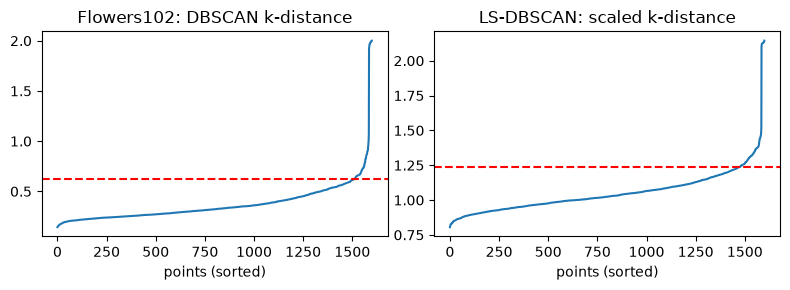

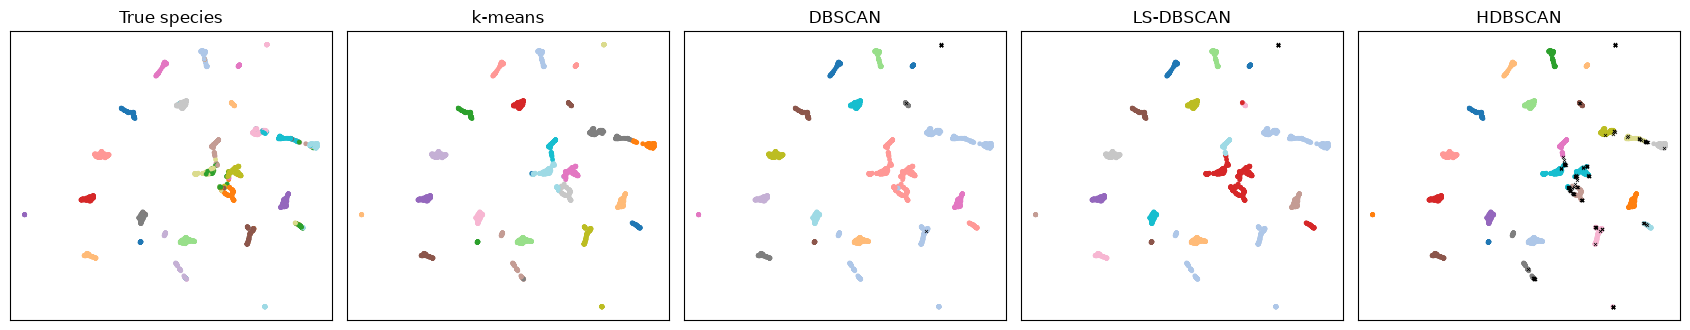

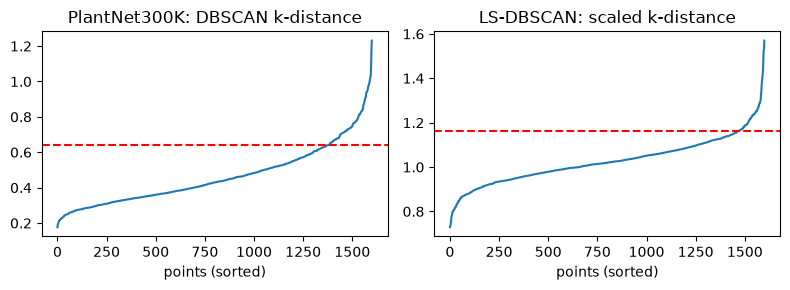

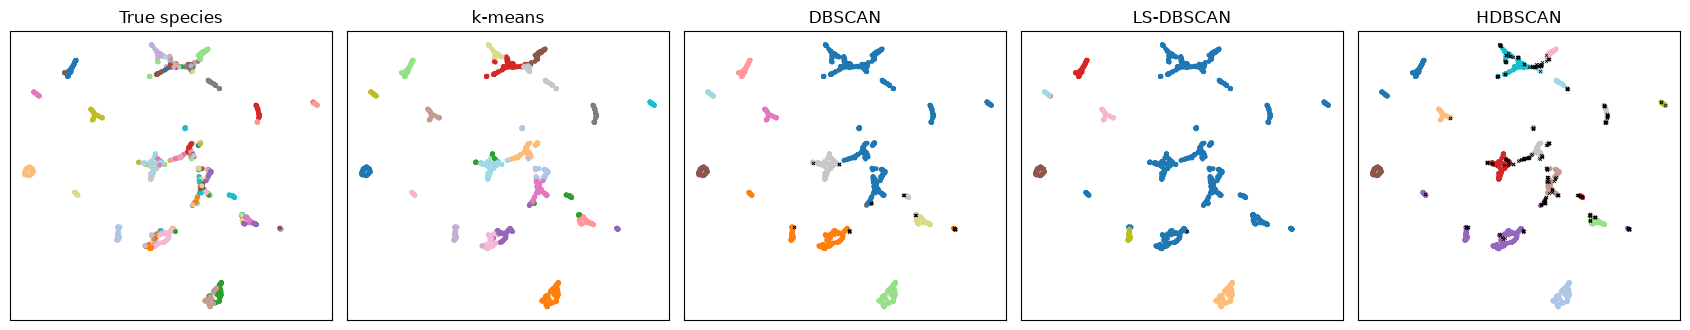

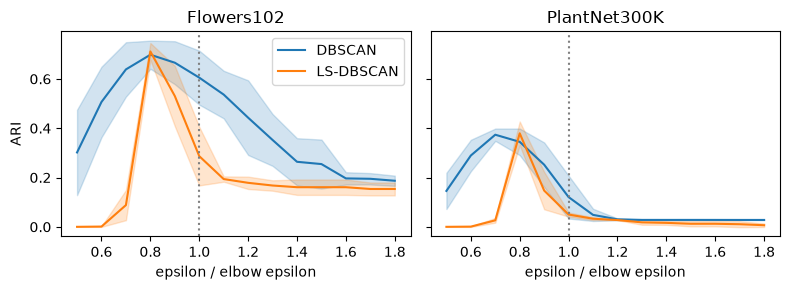

In [6]:
# 5. Figures
for name in DATASETS:
    run = first_run[name]

    # k distance plots (where epsilon comes from)
    fig, ax = plt.subplots(1, 2, figsize=(8, 3))
    ax[0].plot(run["kdist"]); ax[0].axhline(run["eps"], color="r", ls="--")
    ax[0].set_title(f"{name}: DBSCAN k-distance"); ax[0].set_xlabel("points (sorted)")
    ax[1].plot(run["kdist_s"]); ax[1].axhline(run["eps_s"], color="r", ls="--")
    ax[1].set_title("LS-DBSCAN: scaled k-distance"); ax[1].set_xlabel("points (sorted)")
    plt.tight_layout(); plt.savefig(base_dir / f"{name}_kdistance.png", dpi=150); plt.show()

    # clusters in a 2D view (clustering itself was done in 15 dimensions)
    view = umap.UMAP(n_components=2, random_state=0, n_jobs=1).fit_transform(run["Z"])
    fig, ax = plt.subplots(1, 5, figsize=(17, 3.4))
    panels = [("True species", run["y"])] + list(run["labels"].items())
    for a, (title, labels) in zip(ax, panels):
        noise = labels == -1
        a.scatter(view[~noise, 0], view[~noise, 1], c=labels[~noise], cmap="tab20", s=6)
        a.scatter(view[noise, 0], view[noise, 1], c="k", marker="x", s=5, linewidths=0.5)
        a.set_title(title); a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(base_dir / f"{name}_clusters.png", dpi=150); plt.show()

# ARI as epsilon changes
fig, ax = plt.subplots(1, len(DATASETS), figsize=(4 * len(DATASETS), 3), sharey=True)
for a, name in zip(np.atleast_1d(ax), DATASETS):
    for method, color in [("DBSCAN", "C0"), ("LS-DBSCAN", "C1")]:
        part = sweep[(sweep.dataset == name) & (sweep.method == method)]
        curve = part.groupby("factor")["ARI"].agg(["mean", "std"])
        a.plot(curve.index, curve["mean"], color, label=method)
        a.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"],
                       color=color, alpha=0.2)
    a.axvline(1.0, color="gray", ls=":"); a.set_title(name); a.set_xlabel("epsilon / elbow epsilon")
np.atleast_1d(ax)[0].set_ylabel("ARI"); np.atleast_1d(ax)[0].legend()
plt.tight_layout(); plt.savefig(base_dir / "epsilon_sweep.png", dpi=150); plt.show()